Top 10 Artists:                                     track_name     artist_name   streams  \
0                                        SWIM             BTS  11273830   
1                                Body to Body             BTS   6815694   
2                                    Babydoll    Dominic Fike   5733862   
3                                    Hooligan             BTS   5338608   
4                                         FYA             BTS   5196767   
5                                      NORMAL             BTS   4749288   
6  Stateside + Zara Larsson (w/ Zara Larsson)  PinkPantheress   4738329   
7                                      Aliens             BTS   4718569   
8                                           2             BTS   4573989   
9                                Like Animals             BTS   4567309   

   stream_change      7day            genre  country  pos  days  viral_score  \
0       -3370522  25918182            K-Pop       KR    1     2     37192012 

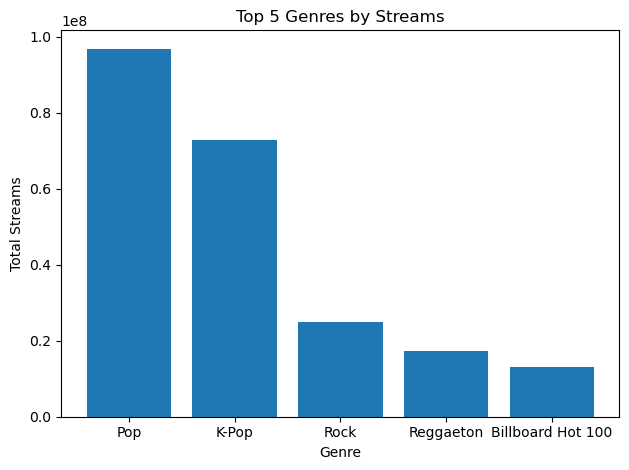

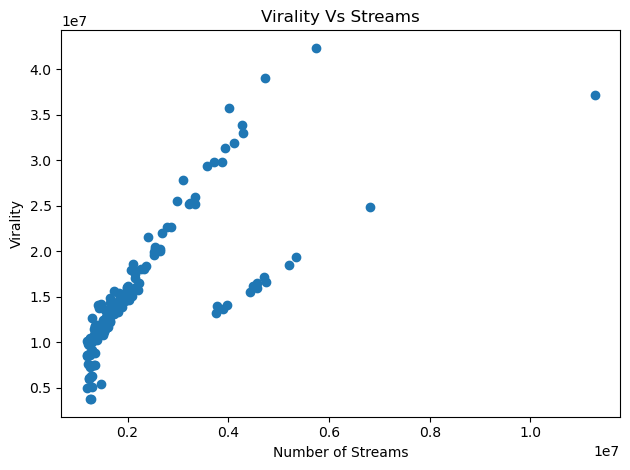


Number of Tracks in Each Trend: 
 trend
Falling    137
Rising      41
Name: pos, dtype: int64


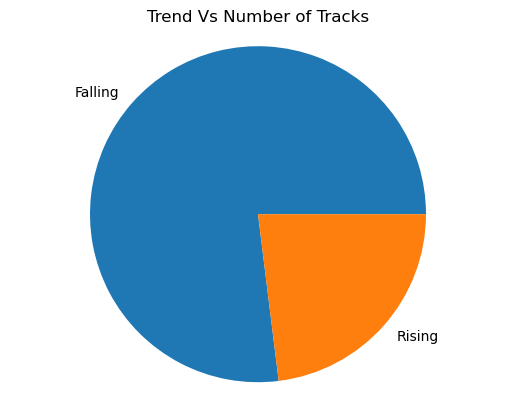

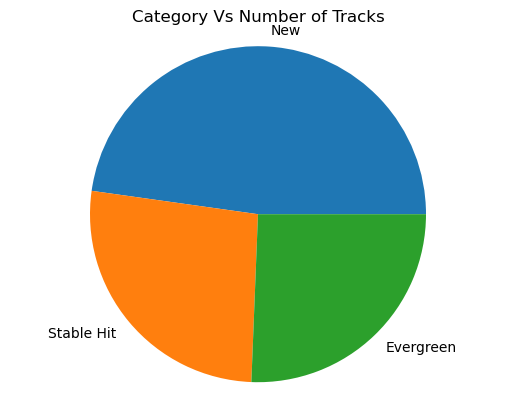


Top 5 Countries: 
 country
US         144060230
KR          76140445
GB          43427153
PR          22457857
England     18154513
CA          14740406
MX          12490791
AU           9164547
Florida      8265098
CO           5960365
Name: streams, dtype: int64


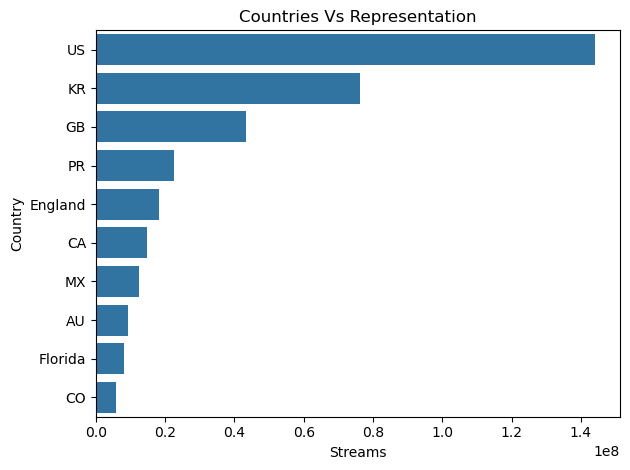


Top 10 Artists With Best Cumulative Change: 
 artist_name
Fuerza Regida         194872
Disney                189999
Jimin                 176731
Benson Boone          129461
Peso Pluma             93365
Lenin Ramírez          90601
Tyler, The Creator     73090
Ryan Castro            64909
KATSEYE                60664
Neton Vega             56324
Name: stream_change, dtype: int64


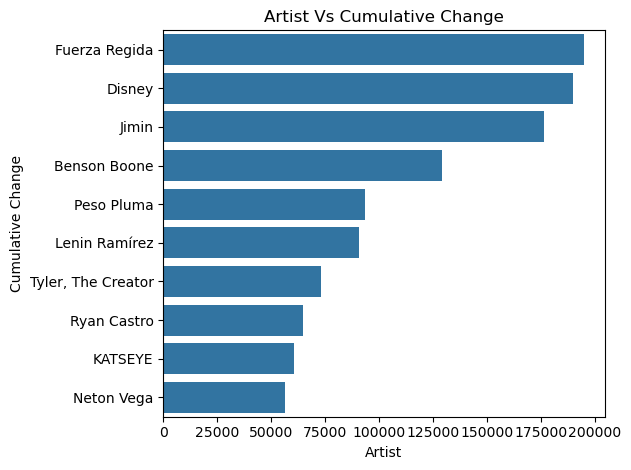

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import string
import math

#Displaying Top 10 Records
#df = pd.read_csv("spotify_global_trends_2026 - spotify_global_trends_final.csv")#uncomment and delete the nextline on labs pc
df = pd.read_csv("spotify_global_trends.csv")
print("Top 10 Artists: ",df.head(10))

#Identifying Uniques
print("\n\nTotal Number of Unique Artists: ", df["artist_name"].nunique())
print("Total Number of Unique Genres: ", df["genre"].nunique())

#Basic Summary Statistics
print("\n\nStreams: \n",df['streams'].describe().loc[["mean","std","min","max","25%","50%","75%"]].astype(int))

print("\nDays: \n",df['days'].describe().loc[["mean","std","min","max","25%","50%","75%"]].astype(int))

print("\nViral Score: \n",df['viral_score'].describe().loc[["mean","std","min","max","25%","50%","75%"]].astype(int))

#Data Cleaning

df['clean_Text_track']=df['track_name'].str.lower()
print("\n\nLower Case: \n",df['clean_Text_track'])

def remove_punc(x):
    t = x.translate(str.maketrans(" "," ",string.punctuation))
    t = t.strip()
    return t

df['clean_Text_track']=df['clean_Text_track'].apply(remove_punc)

print("\nCleaned Track Text:\n", df['clean_Text_track'])

df['clean_Text_artist']=df['artist_name'].str.lower()
print("\n\nLower Case: \n",df['clean_Text_artist'])

def remove_punc(x):
    t = x.translate(str.maketrans(" "," ",string.punctuation))
    t = t.strip()
    return t

df['clean_Text_artist']=df['clean_Text_artist'].apply(remove_punc)

print("\nCleaned Artist Text:\n", df['clean_Text_artist'])

#Top 5 Genres using Streams
streams_genre = df.groupby("genre")["streams"].sum().sort_values(ascending=False)
print("\nTop 5 Genres: \n",streams_genre.head(5))
top5 = streams_genre.head(5)

plt.bar(top5.index,top5.values)
plt.title("Top 5 Genres by Streams")
plt.xlabel("Genre")
plt.ylabel("Total Streams")
plt.tight_layout()
plt.show()

plt.scatter(df['streams'],df['viral_score'])
plt.title("Virality Vs Streams")
plt.xlabel("Number of Streams")
plt.ylabel("Virality")
plt.tight_layout()
plt.show()

trends = df.groupby("trend")["pos"].nunique().sort_values(ascending=False)

print("\nNumber of Tracks in Each Trend: \n",trends)
plt.pie(trends.values,labels = trends.index)
plt.title("Trend Vs Number of Tracks")
plt.axis('equal')
plt.show()

# plt.bar(trends.index,trends.values)
# plt.title("Trend Distribution")
# plt.xlabel("Trends")
# plt.ylabel("Number of Tracks")
# plt.tight_layout()
# plt.show()

longevity = df.groupby("longevity")["streams"].mean().sort_values(ascending=False)
plt.pie(longevity.values,labels=longevity.index)
plt.axis('equal')
plt.title("Category Vs Number of Tracks")

plt.show()

country = df.groupby("country")["streams"].sum().sort_values(ascending=False)
top10 = country.head(10)
print("\nTop 5 Countries: \n",top10)

sns.barplot(y=top10.index,x=top10.values)
plt.title("Countries Vs Representation")
plt.ylabel("Country")
plt.xlabel("Streams")
plt.tight_layout()
plt.show()

stream_change = df.groupby("artist_name")["stream_change"].sum().sort_values(ascending=False)
top10 = stream_change.head(10)
print("\nTop 10 Artists With Best Cumulative Change: \n",top10)
sns.barplot(y=top10.index,x=top10.values)
plt.title("Artist Vs Cumulative Change")
plt.ylabel("Cumulative Change")
plt.xlabel("Artist")
plt.tight_layout()
plt.show()